In [7]:
# This model is adapted from code generated by Claude (Anthropic, 2026), modified by the author.

In [8]:
#Import Data
import zipfile
from pathlib import Path

#DF / Data Manipulation
import numpy as np
import pandas as pd

#Metrics
from sklearn.metrics import classification_report, confusion_matrix, recall_score

#Graphs
import matplotlib.pyplot as plt
from matplotlib.pyplot import clf

#Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from pyexpat import model


Windows: 831 | Features: 64
stand-sit    271
walking      196
standing     185
sitting      179
Name: count, dtype: int64 

Train windows: 580 | Test windows: 243
              precision    recall  f1-score   support

     sitting       0.82      0.81      0.82        52
   stand-sit       0.90      0.80      0.85        80
    standing       0.74      0.89      0.81        54
     walking       1.00      0.98      0.99        57

    accuracy                           0.86       243
   macro avg       0.87      0.87      0.87       243
weighted avg       0.87      0.86      0.87       243



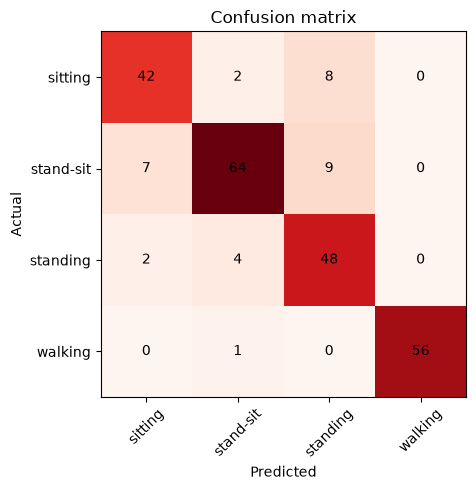

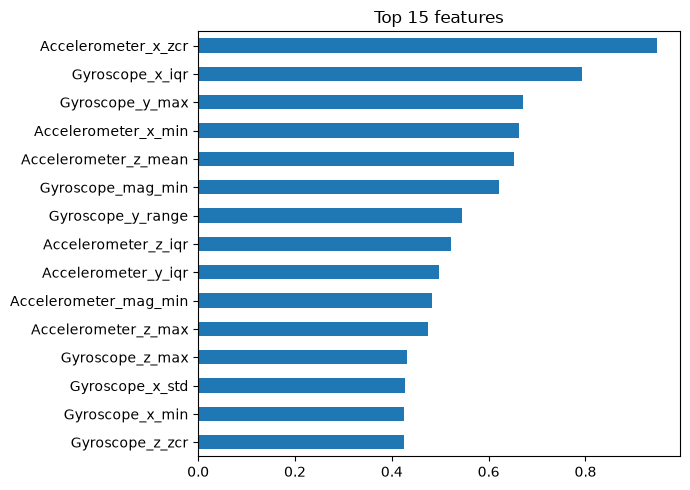

In [ ]:
#CONFIG

DATA_DIR = Path("data")
FS = 50                      # sampling rate
WINDOW_SEC = 2.0             # window length in seconds
OVERLAP = 0.5                # 50% overlap
SENSORS = ["Accelerometer", "Gyroscope"]   
RANDOM_STATE = 42


#LOAD DATA

def load_recording(zip_path: Path) -> pd.DataFrame:
    """Load the chosen sensors from one zip and resample onto a common 50 Hz grid."""
    streams = {}
    with zipfile.ZipFile(zip_path) as zf:
        for sensor in SENSORS:
            name = f"{sensor}.csv"
            if name not in zf.namelist():
                continue
            with zf.open(name) as f:
                df = pd.read_csv(f)
            if df.empty:
                continue
            streams[sensor] = df

    if not streams:
        raise ValueError(f"No usable sensor files in {zip_path}")

    # COMMON 50HZ TIME GRID
    t_start = max(df["seconds_elapsed"].iloc[0] for df in streams.values())
    t_end = min(df["seconds_elapsed"].iloc[-1] for df in streams.values())
    grid = np.arange(t_start, t_end, 1 / FS)

    out = {"t": grid}
    for sensor, df in streams.items():
        for axis in ["x", "y", "z"]:
            out[f"{sensor}_{axis}"] = np.interp(grid, df["seconds_elapsed"], df[axis])
        out[f"{sensor}_mag"] = np.sqrt(
            sum(out[f"{sensor}_{a}"] ** 2 for a in ["x", "y", "z"])
        )
    return pd.DataFrame(out)




#WINDOW FEATURES

def window_features(window: np.ndarray, columns: list[str]) -> dict:
    """Extract time and frequency domain features from one window."""
    feats = {}
    for i, col in enumerate(columns):
        s = window[:, i]
        feats[f"{col}_mean"] = s.mean()
        feats[f"{col}_std"] = s.std()
        feats[f"{col}_min"] = s.min()
        feats[f"{col}_max"] = s.max()
        feats[f"{col}_range"] = s.max() - s.min()
        feats[f"{col}_iqr"] = np.percentile(s, 75) - np.percentile(s, 25)
        feats[f"{col}_energy"] = np.mean(s ** 2)
        feats[f"{col}_zcr"] = np.mean(np.diff(np.sign(s - s.mean())) != 0)

    return feats



#BUILD DF using data from all recordings, split into overlapping windows

def build_dataset():
    rows, labels, groups = [], [], []
    win = int(WINDOW_SEC * FS)
    step = int(win * (1 - OVERLAP))

    for label_dir in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
        label = label_dir.name
        for zip_path in sorted(label_dir.glob("*.zip")):
            df = load_recording(zip_path)
            cols = [c for c in df.columns if c != "t"]
            values = df[cols].to_numpy()

            for start in range(0, len(values) - win + 1, step):
                rows.append(window_features(values[start:start + win], cols))
                labels.append(label)
                groups.append(zip_path.name)  # recording ID, used to prevent leakage

    X = pd.DataFrame(rows)
    return X, np.array(labels), np.array(groups)


#MAIN

def main():
    X, y, groups = build_dataset()
    print(f"Windows: {len(X)} | Features: {X.shape[1]}")
    print(pd.Series(y).value_counts(), "\n")

    train_idx, test_idx = [], []
    GAP = 2  # windows dropped between train and test (windows overlap by 50%)

    for g in np.unique(groups):
        idx = np.where(groups == g)[0]
        cut = int(len(idx) * 0.7) #Train 70% of each recording, test 30%
        train_idx.extend(idx[:cut])
        test_idx.extend(idx[cut + GAP:])

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    print(f"Train windows: {len(X_train)} | Test windows: {len(X_test)}")


    #MODEL

    model = make_pipeline(
        StandardScaler(), #Standardise features for scaling
        LogisticRegression(
            max_iter=5000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
    )
    model.fit(X_train, y_train)
    preds = model.predict(X_test)


    print(classification_report(y_test, preds, zero_division=0))

    # Confusion matrix
    labels_sorted = sorted(set(y))
    cm = confusion_matrix(y_test, preds, labels=labels_sorted)
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap="Reds")
    ax.set_xticks(range(len(labels_sorted)), labels_sorted, rotation=45)
    ax.set_yticks(range(len(labels_sorted)), labels_sorted)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    for i in range(len(labels_sorted)):
        for j in range(len(labels_sorted)):
            ax.text(j, i, cm[i, j], ha="center", va="center")
    plt.title("Confusion matrix")
    plt.tight_layout()
    plt.show()

    # Top 15 features by mean absolute coefficient across classes (features are standardised, so sizes are comparable)
    clf = model.named_steps["logisticregression"]
    coef = pd.DataFrame(clf.coef_.T, index=X.columns, columns=clf.classes_)
    imp = coef.abs().mean(axis=1).nlargest(15)
    imp.sort_values().plot.barh(figsize=(7, 5), title="Top 15 features")
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()